In [42]:
import importlib
import json
import os
import sys
from pathlib import Path

import joblib
import numpy as np
import optuna
import pandas as pd
import shap
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier, XGBRegressor

project_root = Path.cwd()
for candidate_root in (Path.cwd(), *Path.cwd().parents):
    if (candidate_root / "dataset" / "student-por.csv").is_file():
        project_root = candidate_root
        break
else:
    raise FileNotFoundError("Could not find dataset/student-por.csv from the current directory")

modules_path = str(project_root / "modules")
if modules_path not in sys.path:
    sys.path.insert(0, modules_path)

import optuna_classfier

In [40]:


data = pd.read_csv(project_root / "dataset" / "student-por.csv")
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
df = data.drop(columns=["G1", "G2"])

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 31 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [5]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G3            0
dtype: int64

In [6]:
for col in df.columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print(df[col].unique())


school
Unique values: 2
<StringArray>
['GP', 'MS']
Length: 2, dtype: str

sex
Unique values: 2
<StringArray>
['F', 'M']
Length: 2, dtype: str

age
Unique values: 8
[18 17 15 16 19 22 20 21]

address
Unique values: 2
<StringArray>
['U', 'R']
Length: 2, dtype: str

famsize
Unique values: 2
<StringArray>
['GT3', 'LE3']
Length: 2, dtype: str

Pstatus
Unique values: 2
<StringArray>
['A', 'T']
Length: 2, dtype: str

Medu
Unique values: 5
[4 1 3 2 0]

Fedu
Unique values: 5
[4 1 2 3 0]

Mjob
Unique values: 5
<StringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str

Fjob
Unique values: 5
<StringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str

reason
Unique values: 4
<StringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str

guardian
Unique values: 3
<StringArray>
['mother', 'father', 'other']
Length: 3, dtype: str

traveltime
Unique values: 4
[2 1 3 4]

studytime
Unique values: 4
[2 3 1 4]

failures
Unique 

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns
correlation = df[numeric_cols].corr()["G3"].sort_values(ascending=False)
correlation

G3            1.000000
studytime     0.249789
Medu          0.240151
Fedu          0.211800
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64

In [8]:
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(include=["object"]).columns.tolist()
print("Numerical Features:")
print(numeric_features)
print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G3']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\udot\AppData\Local\Temp\ipykernel_3176\3111186415.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=["object"]).columns.tolist()


In [9]:
print(df.shape)
print("G3" in df.columns)

(649, 31)
True


In [10]:
X = df.drop(columns=["G3"])
y = df["G3"]
X.head()
y.head()

0    11
1    11
2    12
3    14
4    13
Name: G3, dtype: int64

In [41]:
X = df.drop(columns=["G3", "G1", "G2"], errors="ignore")
y = df["G3"]

def risk_category(score):
    if score < 10:
        return 0
    if score < 14:
        return 1
    return 2

y_risk = y.apply(risk_category)
X_dev, X_test, y_dev, y_test, risk_dev, risk_test = train_test_split(
    X,
    y,
    y_risk,
    test_size=0.20,
    random_state=42,
    stratify=y_risk,
)

X_train, X_val, y_train, y_val, risk_train, risk_val = train_test_split(
    X_dev,
    y_dev,
    risk_dev,
    test_size=0.20,
    random_state=42,
    stratify=risk_dev,
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (415, 56)
Validation: (104, 56)
Test: (130, 56)


In [43]:
def model(
    X_train_processed,
    y_train,
    X_val_processed,
    y_val,
    X_test_processed,
) -> tuple[XGBRegressor, np.ndarray, float, dict[str, object]]:
    def objective(trial):
        params = {
            "objective": "reg:squarederror",
            "n_estimators": trial.suggest_int("n_estimators", 100, 800),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "gamma": trial.suggest_float("gamma", 0, 5),
            "reg_alpha": trial.suggest_float("reg_alpha", 0, 2),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 5),
        }

        regressor = XGBRegressor(**params, random_state=42)
        regressor.fit(X_train_processed, y_train)
        predictions = regressor.predict(X_val_processed)
        return mean_squared_error(y_val, predictions) ** 0.5

    study = optuna.create_study(direction="minimize")
    study.optimize(objective, n_trials=50)

    best_params = study.best_params
    X_fit = np.concatenate([X_train_processed, X_val_processed])
    y_fit = pd.concat([y_train, y_val])
    best_model = XGBRegressor(**best_params, random_state=42)
    best_model.fit(X_fit, y_fit)
    y_pred = best_model.predict(X_test_processed)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5

    print("Best validation RMSE:", study.best_value)
    print("Best Parameters:")
    print(best_params)

    return best_model, y_pred, rmse, best_params

In [29]:
best_model, y_pred, rmse, best_params = model(
    X_train_processed,
    y_train,
    X_val_processed,
    y_val,
    X_test_processed,
)

[I 2026-10-22 15:39:15,378] A new study created in memory with name: no-name-928a4783-208b-4f5a-ab81-f7d5bd79a75a


[I 2026-10-22 15:39:16,694] Trial 0 finished with value: 2.5559715287200366 and parameters: {'n_estimators': 233, 'learning_rate': 0.138882336240364, 'max_depth': 6, 'min_child_weight': 5, 'subsample': 0.6150502121036795, 'colsample_bytree': 0.9525050381593649, 'gamma': 3.7889239669350294, 'reg_alpha': 1.250222579305906, 'reg_lambda': 2.755553179001583}. Best is trial 0 with value: 2.5559715287200366.
[I 2026-10-22 15:39:20,953] Trial 1 finished with value: 2.5386564428914324 and parameters: {'n_estimators': 544, 'learning_rate': 0.10085439734826404, 'max_depth': 8, 'min_child_weight': 3, 'subsample': 0.8160714957297733, 'colsample_bytree': 0.7433190148175999, 'gamma': 1.512119891706425, 'reg_alpha': 0.8063796901104103, 'reg_lambda': 4.7069177264743205}. Best is trial 1 with value: 2.5386564428914324.
[I 2026-10-22 15:39:23,479] Trial 2 finished with value: 2.6404868546866407 and parameters: {'n_estimators': 454, 'learning_rate': 0.08607039661692836, 'max_depth': 3, 'min_child_weight':

Best validation RMSE: 2.394257820785
Best Parameters:
{'n_estimators': 292, 'learning_rate': 0.07282807843895701, 'max_depth': 9, 'min_child_weight': 5, 'subsample': 0.9280888426282305, 'colsample_bytree': 0.6155853103340946, 'gamma': 3.6216815422659043, 'reg_alpha': 0.25787158711741864, 'reg_lambda': 1.5799249239021864}


In [ ]:
with open(project_root / "modules" / "best_params.json", "w", encoding="utf-8") as file:
    json.dump(best_params, file, indent=4)

print("Best parameters saved successfully!")

Best parameters saved successfully!


In [ ]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 score:", r2)

MSE: 7.133259296417236
RMSE: 2.670816222883416
MAE: 1.9750487804412842
R2 score: 0.26851242780685425


In [17]:
results = pd.DataFrame({
    "Actual G3": y_test.values,
    "Predicted G3": y_pred,
})
results.head()

,Actual G3,Predicted G3
0,19,11.716074
1,12,13.028019
2,18,13.626600
3,11,11.818076
4,11,11.495825


In [36]:
y_train_risk = risk_train
y_test_risk = risk_test

print(y_train_risk.value_counts())
print(y_test_risk.value_counts())

G3
1    227
2    124
0     64
Name: count, dtype: int64
G3
1    71
2    39
0    20
Name: count, dtype: int64


In [37]:
classifier = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
)
classifier.fit(X_train_processed, y_train_risk)
y_pred_risk = classifier.predict(X_test_processed)
accuracy = accuracy_score(y_test_risk, y_pred_risk)
print("Accuracy:", accuracy)
print("\nClassification Report:")
print(
    classification_report(
        y_test_risk,
        y_pred_risk,
        labels=[0, 1, 2],
        target_names=["High Risk", "Medium Risk", "Low Risk"],
        zero_division=0,
    )
)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_risk, y_pred_risk, labels=[0, 1, 2]))

Accuracy: 0.6153846153846154

Classification Report:
              precision    recall  f1-score   support

   High Risk       0.50      0.25      0.33        20
 Medium Risk       0.67      0.76      0.71        71
    Low Risk       0.54      0.54      0.54        39

    accuracy                           0.62       130
   macro avg       0.57      0.52      0.53       130
weighted avg       0.60      0.62      0.60       130


Confusion Matrix:
[[ 5  9  6]
 [ 5 54 12]
 [ 0 18 21]]


In [34]:
importlib.reload(optuna_classfier)

<module 'optuna_classfier' from 'c:\\Users\\udot\\OneDrive\\Desktop\\New folder\\AI-Powered-Student-Achievement-Intelligence-Platform\\modules\\optuna_classfier.py'>

In [38]:
importlib.reload(optuna_classfier)
best_classifier, y_pred_risk, macro_f1 = optuna_classfier.classifier(
    X_train_processed,
    y_train_risk,
    X_val_processed,
    risk_val,
    X_test_processed,
    y_test_risk,
)
print("Optimized test Macro F1:", macro_f1)

[I 2026-10-22 15:43:08,724] A new study created in memory with name: no-name-c2a32947-504f-45da-a361-239ba8b77676
[I 2026-10-22 15:43:10,944] Trial 0 finished with value: 0.4250077694130962 and parameters: {'n_estimators': 542, 'learning_rate': 0.07234769848182185, 'max_depth': 6, 'min_child_weight': 10, 'subsample': 0.8829547216131435, 'colsample_bytree': 0.6614402916735139, 'gamma': 2.33401876037546, 'reg_alpha': 0.3304424329875655, 'reg_lambda': 0.4426616459412779}. Best is trial 0 with value: 0.4250077694130962.
[I 2026-10-22 15:43:12,424] Trial 1 finished with value: 0.357940797940798 and parameters: {'n_estimators': 373, 'learning_rate': 0.06843434449921995, 'max_depth': 7, 'min_child_weight': 4, 'subsample': 0.9205719797614123, 'colsample_bytree': 0.7400242673591872, 'gamma': 3.2709554902572635, 'reg_alpha': 1.767795864081529, 'reg_lambda': 2.9430917443784272}. Best is trial 0 with value: 0.4250077694130962.
[I 2026-10-22 15:43:15,113] Trial 2 finished with value: 0.338922176670

Best Macro F1: 0.4953520926060972

Best Parameters:
{'n_estimators': 679, 'learning_rate': 0.010028526075061484, 'max_depth': 6, 'min_child_weight': 7, 'subsample': 0.853489339788656, 'colsample_bytree': 0.6579610638924497, 'gamma': 0.2917965851693131, 'reg_alpha': 1.954686059581284, 'reg_lambda': 1.732179330344602}
Optimized test Macro F1: 0.5139550264550264


In [ ]:
accuracy_optimized = accuracy_score(y_test_risk, y_pred_risk)

print("Optimized Accuracy:", accuracy_optimized)
print("\nOptimized Classification Report:")
print(
    classification_report(
        y_test_risk,
        y_pred_risk,
        labels=[0, 1, 2],
        target_names=["High Risk", "Medium Risk", "Low Risk"],
        zero_division=0,
    )
)

print("\nOptimized Confusion Matrix:")
print(confusion_matrix(y_test_risk, y_pred_risk, labels=[0, 1, 2]))

Optimized Accuracy: 0.676923076923077

Optimized Classification Report:
              precision    recall  f1-score   support

   High Risk       0.60      0.40      0.48        15
 Medium Risk       0.69      0.79      0.74        71
    Low Risk       0.67      0.59      0.63        44

    accuracy                           0.68       130
   macro avg       0.65      0.59      0.61       130
weighted avg       0.67      0.68      0.67       130


Optimized Confusion Matrix:
[[ 6  7  2]
 [ 4 56 11]
 [ 0 18 26]]


In [23]:
feature_names = preprocessor.get_feature_names_out()
print("Number of features:", len(feature_names))

Number of features: 56


In [24]:
explainer = shap.TreeExplainer(best_classifier)
shap_values = explainer.shap_values(X_test_processed)

print(type(shap_values))

<class 'numpy.ndarray'>


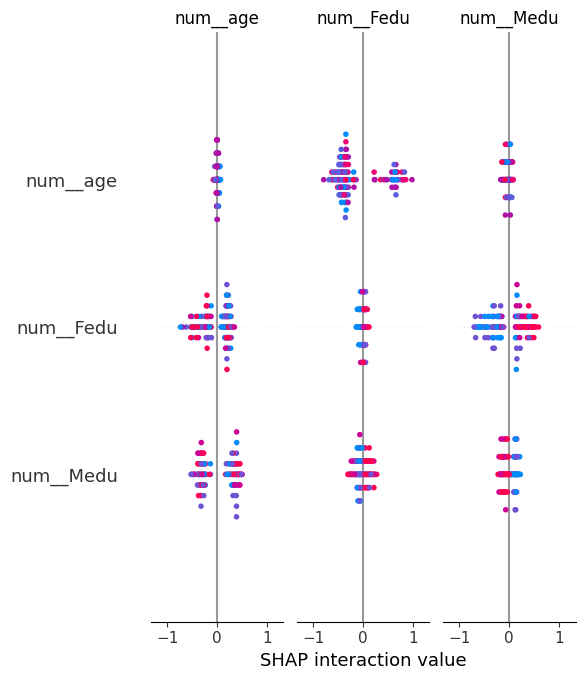

In [25]:
shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names
)

In [35]:
os.makedirs("models", exist_ok=True)
joblib.dump(preprocessor, "models/preprocessor.joblib")
joblib.dump(best_model, "models/regression_model.joblib")

['models/regression_model.joblib']